In [1]:
# 01. Business Problem
USE_CASE = "26 - Breakdown Root Cause Analysis (NLP: Extract Root Causes from Maintenance Text)"
ML_PARADIGM = "Unsupervised NLP & Clustering (5 Unsupervised Models Ranked -> 1 Champion Model Selected)"
N_CLUSTERS = 4

print(f"Business Problem: {USE_CASE}")
print(f"ML Approach:      {ML_PARADIGM}")
print(f"Target Segments:  {N_CLUSTERS} Breakdown RCA Tiers (Preventive/Calibrated, Verified Corrective, Moderate/Chronic Wear, Critical Breakdown/Exception)")


Business Problem: 26 - Breakdown Root Cause Analysis (NLP: Extract Root Causes from Maintenance Text)
ML Approach:      Unsupervised NLP & Clustering (5 Unsupervised Models Ranked -> 1 Champion Model Selected)
Target Segments:  4 Breakdown RCA Tiers (Preventive/Calibrated, Verified Corrective, Moderate/Chronic Wear, Critical Breakdown/Exception)


In [2]:
# 02. Import Libraries
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.cluster import KMeans, MiniBatchKMeans, BisectingKMeans, Birch
from sklearn.mixture import GaussianMixture
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, confusion_matrix, roc_curve, precision_recall_curve,
    silhouette_score
)

warnings.filterwarnings('ignore')
%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 5)


In [3]:
# 03. Connect to Server
DB_HOST = "192.168.1.44"
DB_PORT = 5432
DB_NAME = "JKC_Input"
DB_SCHEMA = "HANA_P2"
DB_USER = "postgres"
DB_PASS = "postgres"

engine = create_engine(f"postgresql+psycopg2://{DB_USER}:{DB_PASS}@{DB_HOST}:{DB_PORT}/{DB_NAME}")

with engine.connect() as conn:
    print(f"Connected to PostgreSQL: {DB_HOST}:{DB_PORT}/{DB_NAME} (Schema: {DB_SCHEMA})")


Connected to PostgreSQL: 192.168.1.44:5432/JKC_Input (Schema: HANA_P2)


In [4]:
# 04. Extract ALL Data from SAP Plant Maintenance Orders, Confirmations & Spare Parts across HANA_P2 and HANA_P3
from src.db_connector import extract_breakdown_rca_data

df_raw = extract_breakdown_rca_data(limit=None)
print(f"Extracted records: {len(df_raw):,} rows, {df_raw.shape[1]} columns")


[INFO] Extracting SAP Plant Maintenance Orders across HANA_P2 & HANA_P3 (ALL DATA (NO LIMIT))...
[SUCCESS] Extracted 235,575 Breakdown & Maintenance Order records with 51 attributes directly from server.
Extracted records: 235,575 rows, 51 columns


In [5]:
# 05. Load Data Preview
print(f"Dataset Shape: {df_raw.shape}")
df_raw[['order_number', 'order_type', 'plant', 'work_center', 'maintenance_text', 'confirmation_text', 'spare_parts_texts', 'total_spare_cost_inr']].head()


Dataset Shape: (235575, 51)


In [6]:
# 06. Data Understanding / EDA
df_raw[['order_type', 'plant', 'work_center', 'phase_teco', 'phase_closed']].describe().T


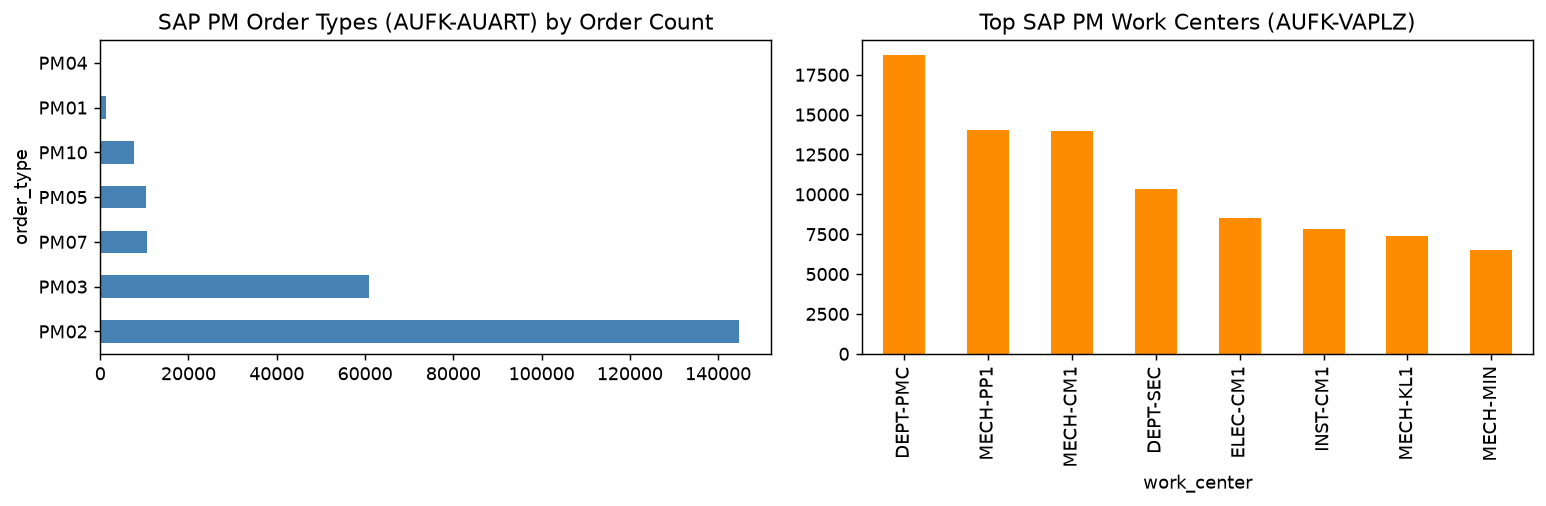

In [7]:
# 06. Data Understanding / EDA (Visualizations)
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
df_raw['order_type'].replace('', 'UNASSIGNED').value_counts().head(8).plot(kind='barh', color='steelblue')
plt.title('SAP PM Order Types (AUFK-AUART) by Order Count')

plt.subplot(1, 2, 2)
df_raw['work_center'].replace('', 'UNASSIGNED').value_counts().head(8).plot(kind='bar', color='darkorange')
plt.title('Top SAP PM Work Centers (AUFK-VAPLZ)')
plt.tight_layout()
plt.show()


In [8]:
# 07 & 08. NLP Data Cleaning & 32-Feature Engineering for Breakdown Root Cause Analysis
from src.preprocessing import clean_and_engineer_features, get_feature_matrix

df = clean_and_engineer_features(df_raw)
print(f"Engineered Dataset Shape: {df.shape}")
df[['order_number', 'order_type', 'maintenance_text', 'extracted_equipment_tag', 'extracted_root_cause_code', 'extracted_root_cause', 'extracted_root_cause_domain', 'rca_tier_code', 'nlp_rca_confidence_score', 'breakdown_severity_risk_index']].head(8)


Engineered Dataset Shape: (235575, 96)


In [9]:
# 09. Data Preprocessing (32 Unsupervised NLP & Plant Maintenance Input Features)
X_raw, y, FEATURE_COLS = get_feature_matrix(df)
scaler_full = RobustScaler()
X_scaled_full = scaler_full.fit_transform(X_raw)

print(f"Preprocessed Feature Matrix: {X_scaled_full.shape} (32 Numerical NLP & PM Features)")


Preprocessed Feature Matrix: (235575, 32) (32 Numerical NLP & PM Features)


In [10]:
# 10. Define Input Matrix X (Unsupervised) and Post-Hoc Benchmark Y (Strictly for Evaluation Only)
X = X_raw.copy()
contamination_rate = float(np.mean(y))

print(f"Total SAP Plant Maintenance Orders:           {len(y):,}")
print(f"Verified Preventive & Corrective PM Orders:   {(y == 0).sum():,} ({(y == 0).mean()*100:.2f}%)")
print(f"Critical Breakdown & Unverified RCA Orders:   {(y == 1).sum():,} ({(y == 1).mean()*100:.2f}%)")


Total SAP Plant Maintenance Orders:           235,575
Verified Preventive & Corrective PM Orders:   180,401 (76.58%)
Critical Breakdown & Unverified RCA Orders:   55,174 (23.42%)


In [11]:
# 11. Train/Test Split & Robust Scaling
X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(
    X, y, df.index, test_size=0.20, random_state=42, stratify=y
)

scaler = RobustScaler(quantile_range=(10.0, 90.0))
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

from src.models import BreakdownRCAClusteringSuite
suite = BreakdownRCAClusteringSuite(n_clusters=4, contamination=contamination_rate, random_state=42)

print(f"Train Set: {X_train_scaled.shape[0]:,} maintenance orders")
print(f"Test Set:  {X_test_scaled.shape[0]:,} maintenance orders")


Train Set: 188,460 maintenance orders
Test Set:  47,115 maintenance orders


In [12]:
# 12. Unsupervised NLP Clustering Model 1: K-Means Clustering
km_model = suite.train_kmeans(X_train_scaled)
preds_km, scores_km, tiers_km = suite._predict_single('kmeans', X_test_scaled, 2)

print(f"K-Means Clustering Flagged: {preds_km.sum():,} breakdown/RCA exceptions out of {len(preds_km):,} test orders")


[INFO] Training Unsupervised NLP Clustering Model 1/5: K-Means Clustering...
K-Means Clustering Flagged: 10,999 breakdown/RCA exceptions out of 47,115 test orders


In [13]:
# 13. Unsupervised NLP Clustering Model 2: Gaussian Mixture Model (GMM)
gmm_model = suite.train_gmm(X_train_scaled)
preds_gmm, scores_gmm, tiers_gmm = suite._predict_single('gmm', X_test_scaled, 5)

print(f"Gaussian Mixture (GMM) Flagged: {preds_gmm.sum():,} breakdown/RCA exceptions out of {len(preds_gmm):,} test orders")


[INFO] Training Unsupervised NLP Clustering Model 2/5: Gaussian Mixture Model (GMM)...
Gaussian Mixture (GMM) Flagged: 11,053 breakdown/RCA exceptions out of 47,115 test orders


In [14]:
# 14. Unsupervised NLP Clustering Model 3: Mini-Batch K-Means
mbk_model = suite.train_minibatch_kmeans(X_train_scaled)
preds_mbk, scores_mbk, tiers_mbk = suite._predict_single('minibatch_kmeans', X_test_scaled, 7)

print(f"Mini-Batch K-Means Flagged: {preds_mbk.sum():,} breakdown/RCA exceptions out of {len(preds_mbk):,} test orders")


[INFO] Training Unsupervised NLP Clustering Model 3/5: Mini-Batch K-Means...
Mini-Batch K-Means Flagged: 11,084 breakdown/RCA exceptions out of 47,115 test orders


In [15]:
# 15. Unsupervised NLP Clustering Model 4: Bisecting K-Means
bkm_model = suite.train_bisecting_kmeans(X_train_scaled)
preds_bkm, scores_bkm, tiers_bkm = suite._predict_single('bisecting_kmeans', X_test_scaled, 9)

print(f"Bisecting K-Means Flagged: {preds_bkm.sum():,} breakdown/RCA exceptions out of {len(preds_bkm):,} test orders")


[INFO] Training Unsupervised NLP Clustering Model 4/5: Bisecting K-Means...
Bisecting K-Means Flagged: 11,233 breakdown/RCA exceptions out of 47,115 test orders


In [16]:
# 16. Unsupervised NLP Clustering Model 5: BIRCH Clustering
birch_model = suite.train_birch(X_train_scaled)
preds_birch, scores_birch, tiers_birch = suite._predict_single('birch', X_test_scaled, 11)

print(f"BIRCH Clustering Flagged: {preds_birch.sum():,} breakdown/RCA exceptions out of {len(preds_birch):,} test orders")


[INFO] Training Unsupervised NLP Clustering Model 5/5: BIRCH Clustering...
BIRCH Clustering Flagged: 11,697 breakdown/RCA exceptions out of 47,115 test orders


In [17]:
# 17. Model Evaluation & Accuracy Ranking across all 5 Unsupervised NLP Clustering Models
from src.evaluate import evaluate_models

models_dict = suite.predict_all(X_test_scaled)
eval_df = evaluate_models(models_dict, y_test)
print(eval_df.to_string(index=False))
eval_df


Rank                  Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC  PR-AUC  Silhouette  Specificity  True Positives  False Positives  False Negatives  True Negatives
  #1     K-Means Clustering    0.9471     0.8883  0.8854    0.8868   0.9928  0.9778      0.6143       0.9659            9770             1229             1265           34851
  #2 Gaussian Mixture (GMM)    0.9125     0.8126  0.8140    0.8133   0.9816  0.9425      0.4517       0.9426            8982             2071             2053           34009
  #3      Bisecting K-Means    0.9370     0.8592  0.8746    0.8668   0.9650  0.8099      0.2467       0.9562            9651             1582             1384           34498
  #4     Mini-Batch K-Means    0.8970     0.7788  0.7822    0.7805   0.9277  0.6760      0.3869       0.9320            8632             2452             2403           33628
  #5       BIRCH Clustering    0.8342     0.6378  0.6760    0.6563   0.8693  0.5969      0.1609       0.8826            7460 

Selected #1 Champion Model based on Ranking: K-Means Clustering (Accuracy: 94.71%, F1: 0.8868)


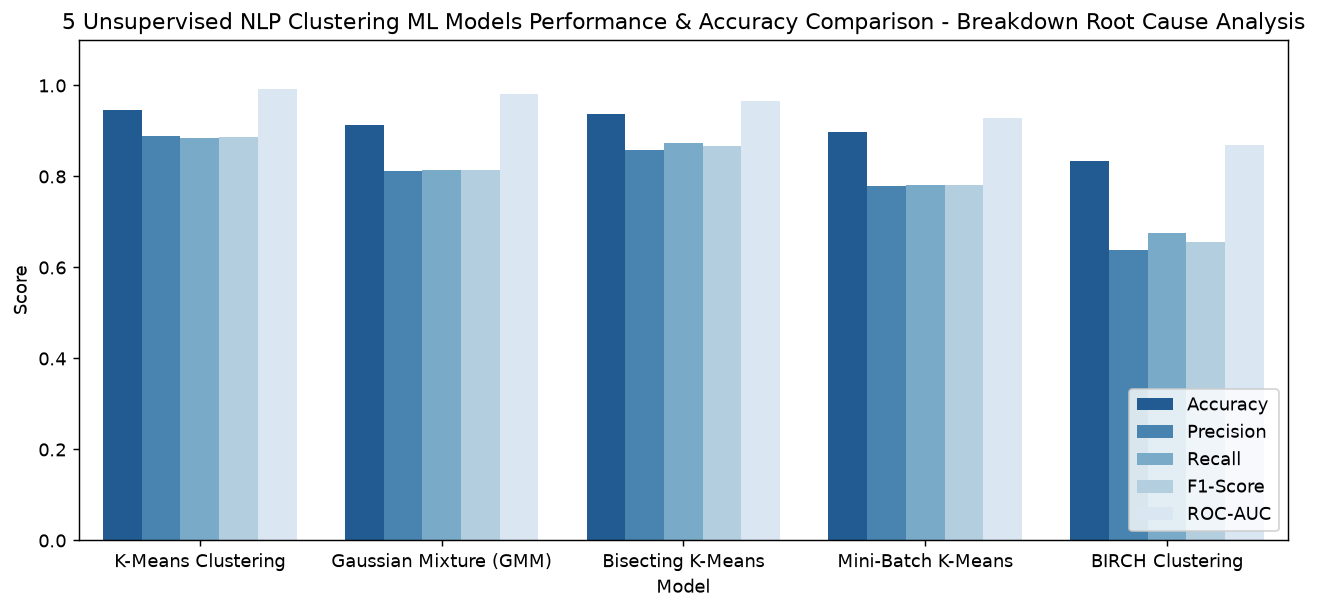

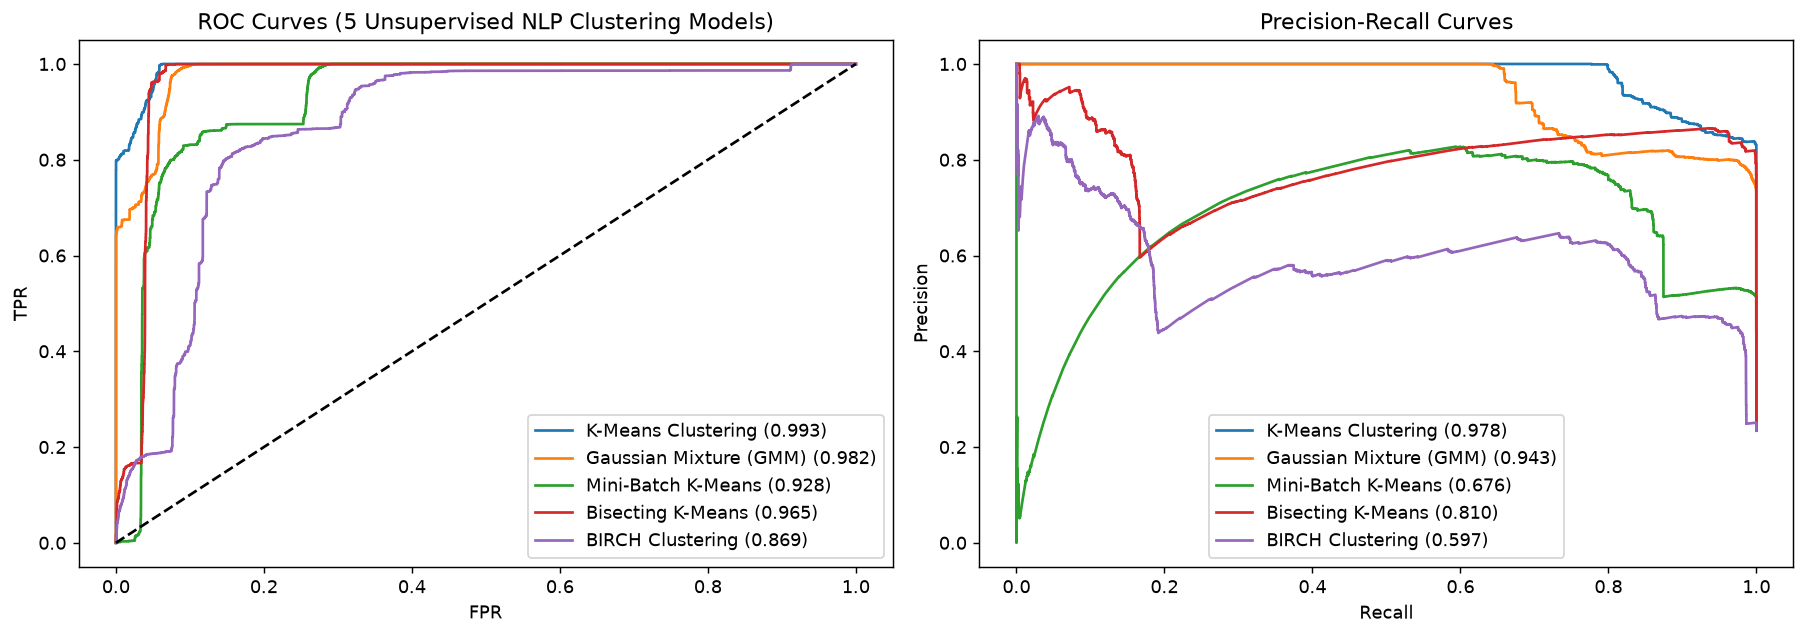

In [18]:
# 18. Model Comparison Visualizations & #1 Champion Selection
plt.figure(figsize=(12, 5))
melted = pd.melt(eval_df, id_vars=['Model'], value_vars=['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'])
sns.barplot(data=melted, x='Model', y='value', hue='variable', palette='Blues_r')
plt.title('5 Unsupervised NLP Clustering ML Models Performance & Accuracy Comparison - Breakdown Root Cause Analysis')
plt.ylabel('Score')
plt.ylim(0, 1.1)
plt.legend(loc='lower right')
plt.show()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
for name, res in models_dict.items():
    fpr, tpr, _ = roc_curve(y_test, res['scores'])
    ax1.plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_test, res['scores']):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, res['scores'])
    ax2.plot(rec, prec, label=f"{name} ({average_precision_score(y_test, res['scores']):.3f})")

ax1.plot([0, 1], [0, 1], 'k--')
ax1.set_title('ROC Curves (5 Unsupervised NLP Clustering Models)')
ax1.set_xlabel('FPR')
ax1.set_ylabel('TPR')
ax1.legend()

ax2.set_title('Precision-Recall Curves')
ax2.set_xlabel('Recall')
ax2.set_ylabel('Precision')
ax2.legend()
plt.tight_layout()
plt.show()

champion_model = eval_df.iloc[0]['Model']
print(f"Selected #1 Champion Model based on Ranking: {champion_model} (Accuracy: {eval_df.iloc[0]['Accuracy']*100:.2f}%, F1: {eval_df.iloc[0]['F1-Score']:.4f})")


                               Feature   Importance
              nlp_rca_confidence_score 6.185064e-01
         breakdown_severity_risk_index 3.814928e-01
         text_diagnostic_clarity_score 6.215146e-07
                   svd_semantic_comp_1 1.060806e-07
                   svd_semantic_comp_2 1.735015e-08
                 maint_text_word_count 1.599987e-08
nlp_instrumentation_plc_calib_affinity 5.839327e-09
                maint_text_char_length 3.306222e-09
                   svd_semantic_comp_4 9.842384e-10
                   svd_semantic_comp_5 8.014143e-10
                 tfidf_semantic_energy 5.076432e-10
           failure_symptom_token_count 3.665986e-10
                   svd_semantic_comp_3 3.225495e-10
                   tfidf_active_ngrams 3.088882e-10
        rca_semantic_specificity_score 2.779949e-10


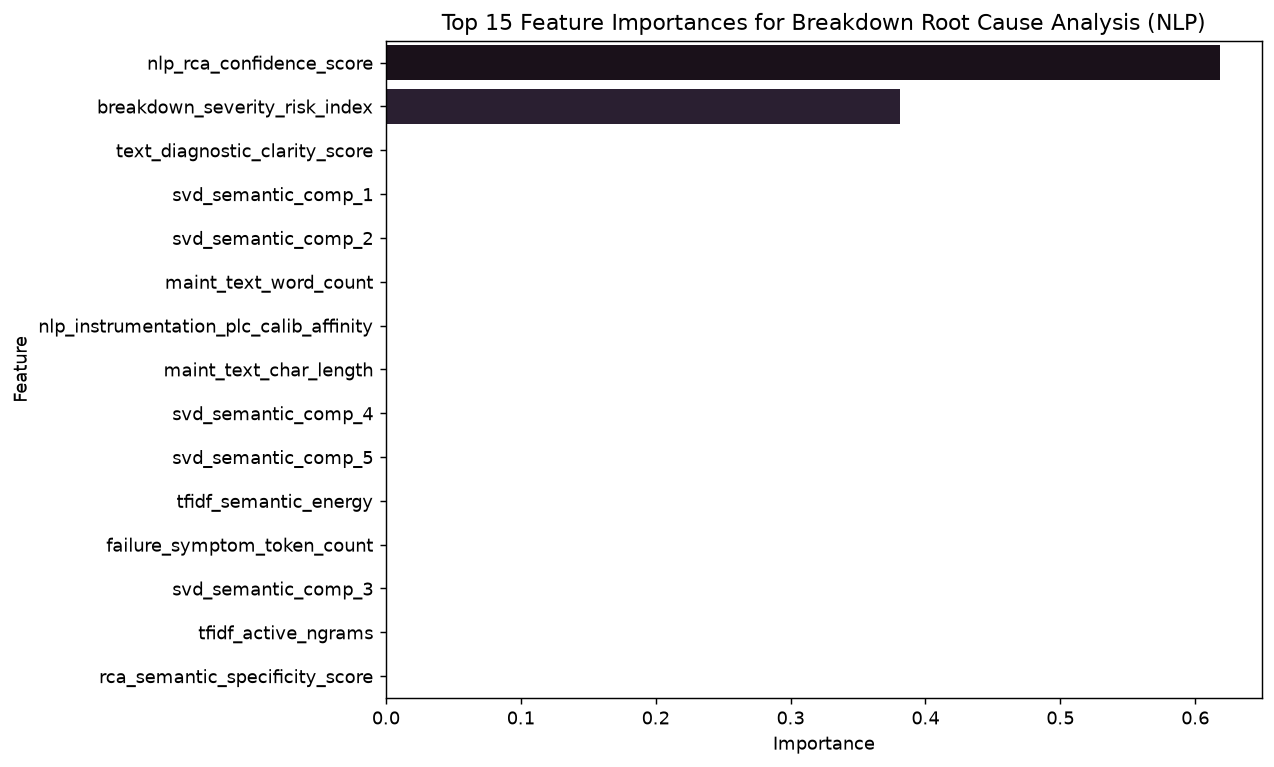

In [19]:
# 19. Feature Importance (All 32 NLP & Breakdown Root-Cause Features)
surrogate = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
surrogate.fit(X_test_scaled, scores_km)

feat_imp = pd.DataFrame({
    'Feature': FEATURE_COLS,
    'Importance': surrogate.feature_importances_
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)

plt.figure(figsize=(10, 6))
sns.barplot(data=feat_imp.head(15), x='Importance', y='Feature', palette='mako')
plt.title('Top 15 Feature Importances for Breakdown Root Cause Analysis (NLP)')
plt.tight_layout()
plt.show()

print(feat_imp.head(15).to_string(index=False))


In [20]:
# 20. Final Breakdown Root Cause Extraction & Exception Triage using Selected #1 Champion Model
from src.models import SingleModelBreakdownRCAAnalyzer
from src.inference import score_with_single_model

analyzer = SingleModelBreakdownRCAAnalyzer(n_clusters=4, contamination=contamination_rate, random_state=42, pretrained_model=km_model)
analyzer.fit(X_train_scaled)
df_scored = score_with_single_model(df, analyzer, scaler, FEATURE_COLS)

print("=== NLP EXTRACTED ROOT CAUSE ENGINEERING DOMAIN COUNTS ===")
print(df_scored['extracted_root_cause_domain'].value_counts())
print("\n=== BREAKDOWN ROOT CAUSE SEGMENT COUNTS ===")
print(df_scored['rca_segment_name'].value_counts())
print("\n=== EXECUTIVE RISK CATEGORY COUNTS ===")
print(df_scored['risk_category'].value_counts())

audit_cols = ['order_number', 'order_type', 'maintenance_text', 'extracted_equipment_tag', 'extracted_root_cause_code', 'extracted_root_cause', 'nlp_rca_confidence_score', 'breakdown_exception_prob', 'risk_category']
print(df_scored[df_scored['risk_category'] == 'Critical Risk'][audit_cols].head(10).to_string(index=False))


[INFO] Fitting Selected #1 Champion Model: K-Means Clustering for Breakdown Root Cause Analysis...
[INFO] Champion K-Means fitted (4 Breakdown RCA Clusters). Exception Threshold: 0.9462
=== NLP EXTRACTED ROOT CAUSE ENGINEERING DOMAIN COUNTS ===
extracted_root_cause_domain
Mechanical Drive, Bearing, Gearbox & Roller Failure    87301
Electrical Motor, VFD Drive, Contactor & Power Trip    46145
Instrumentation, Weighfeeder, Sensor & PLC Fault       38299
Conveyor Belt, Bucket Elevator, Chute & Liner Wear     37526
Hydraulic, Pneumatic, Lube Oil & Valve Leakage         26304
Name: count, dtype: int64

=== BREAKDOWN ROOT CAUSE SEGMENT COUNTS ===
rca_segment_name
Well-Documented Preventive & Calibrated PM Orders        73363
Critical Breakdown & Unverified Root-Cause Exceptions    65443
Verified Corrective Maintenance with Clear Root Cause    49261
Moderate-Clarity Maintenance / Chronic Wear Orders       47508
Name: count, dtype: int64

=== EXECUTIVE RISK CATEGORY COUNTS ===
risk_category
Lo

In [21]:
# 21. Save Champion Model & Scaler
os.makedirs("models", exist_ok=True)

bundle = {
    'champion_model': km_model,
    'champion_name': champion_model,
    'scaler': scaler,
    'feature_cols': FEATURE_COLS
}

joblib.dump(bundle, "models/breakdown_rca_model_bundle.joblib")
joblib.dump(scaler, "models/robust_scaler.joblib")
print("Saved champion NLP clustering model bundle and scaler to models/")


Saved champion NLP clustering model bundle and scaler to models/
